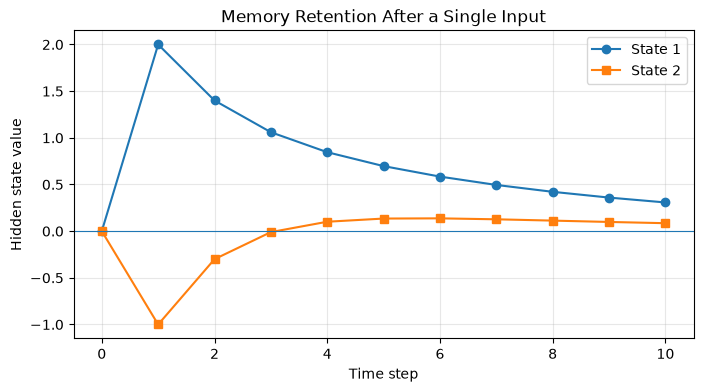

In [3]:

import torch
import matplotlib.pyplot as plt

A = torch.tensor([
    [0.8, 0.2],
    [0.1, 0.5]
], dtype=torch.float64)

B = torch.tensor([2.0, -1.0], dtype=torch.float64)
h = torch.zeros(2, dtype=torch.float64)

history = [h.clone()]
inputs = [1] + [0] * 9

for x in inputs:
    h = A @ h + B * x
    history.append(h.clone())

states = torch.stack(history).numpy()

plt.figure(figsize=(8, 4))
plt.plot(states[:, 0], marker="o", label="State 1")
plt.plot(states[:, 1], marker="s", label="State 2")

plt.axhline(0, linewidth=0.8)
plt.xlabel("Time step")
plt.ylabel("Hidden state value")
plt.title("Memory Retention After a Single Input")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Decay: eigenvalues = [(0.8+0j), (0.5+0j)]
Persistence: eigenvalues = [(1+0j), (0.5+0j)]
Oscillation: eigenvalues = [(-0.8+0j), (0.5+0j)]
Instability: eigenvalues = [(1.2+0j), (0.5+0j)]


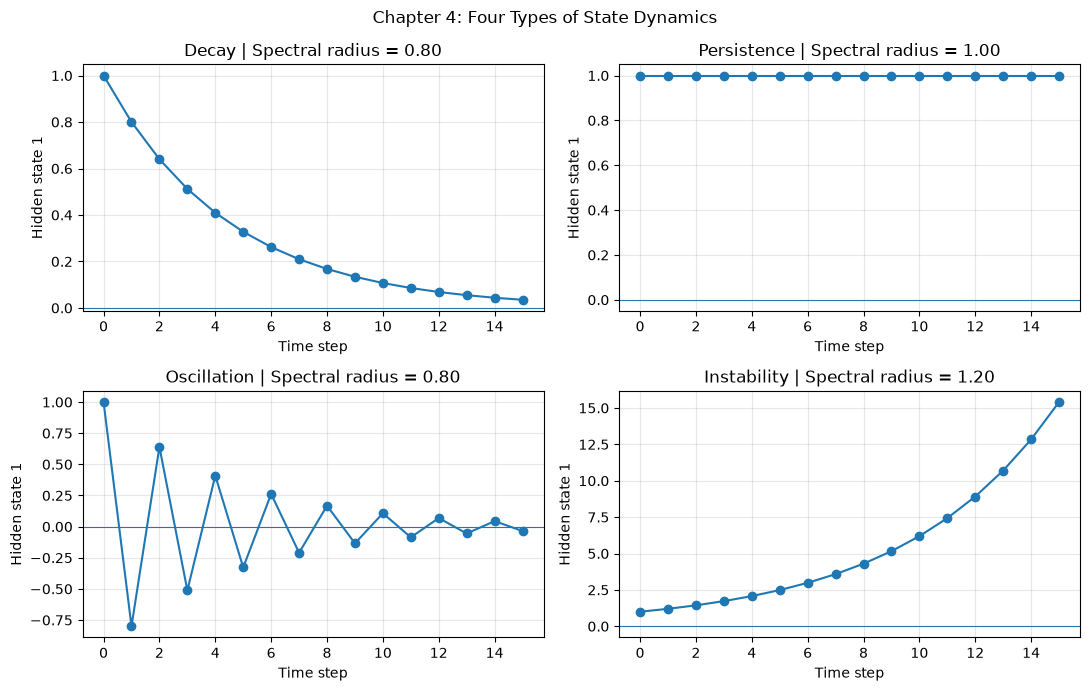

In [4]:

from pathlib import Path

plot_dir = Path("plots")
plot_dir.mkdir(exist_ok=True)

def simulate(A, h0, steps=15):
    h = h0.clone()
    history = [h.clone()]

    for _ in range(steps):
        h = A @ h
        history.append(h.clone())

    return torch.stack(history).numpy()

cases = {
    "Decay": [0.8, 0.5],
    "Persistence": [1.0, 0.5],
    "Oscillation": [-0.8, 0.5],
    "Instability": [1.2, 0.5],
}

fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for ax, (name, diagonal) in zip(axes.flat, cases.items()):
    A_case = torch.diag(
        torch.tensor(diagonal, dtype=torch.float64)
    )

    h0 = torch.tensor([1.0, 0.0], dtype=torch.float64)
    trajectory = simulate(A_case, h0)

    eigenvalues = torch.linalg.eigvals(A_case)
    rho = eigenvalues.abs().max().item()

    ax.plot(trajectory[:, 0], marker="o")
    ax.axhline(0, linewidth=0.8)
    ax.set_title(f"{name} | Spectral radius = {rho:.2f}")
    ax.set_xlabel("Time step")
    ax.set_ylabel("Hidden state 1")
    ax.grid(alpha=0.3)

    print(f"{name}: eigenvalues = {eigenvalues.tolist()}")

plt.suptitle("Chapter 4: Four Types of State Dynamics")
plt.tight_layout()
plt.savefig(plot_dir / "stability_cases.png", dpi=160)
plt.show()


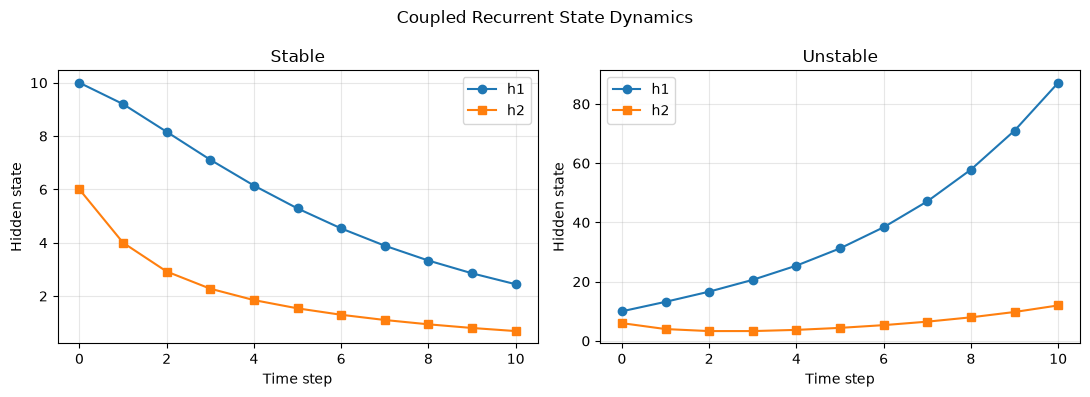

In [5]:

A_stable = torch.tensor([
    [0.8, 0.2],
    [0.1, 0.5]
], dtype=torch.float64)

A_unstable = torch.tensor([
    [1.2, 0.2],
    [0.1, 0.5]
], dtype=torch.float64)

h0 = torch.tensor([10.0, 6.0], dtype=torch.float64)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, A_case) in zip(
    axes,
    [("Stable", A_stable), ("Unstable", A_unstable)]
):
    trajectory = simulate(A_case, h0, steps=10)

    ax.plot(trajectory[:, 0], marker="o", label="h1")
    ax.plot(trajectory[:, 1], marker="s", label="h2")

    ax.set_title(name)
    ax.set_xlabel("Time step")
    ax.set_ylabel("Hidden state")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Coupled Recurrent State Dynamics")
plt.tight_layout()
plt.savefig(plot_dir / "coupled_dynamics.png", dpi=160)
plt.show()


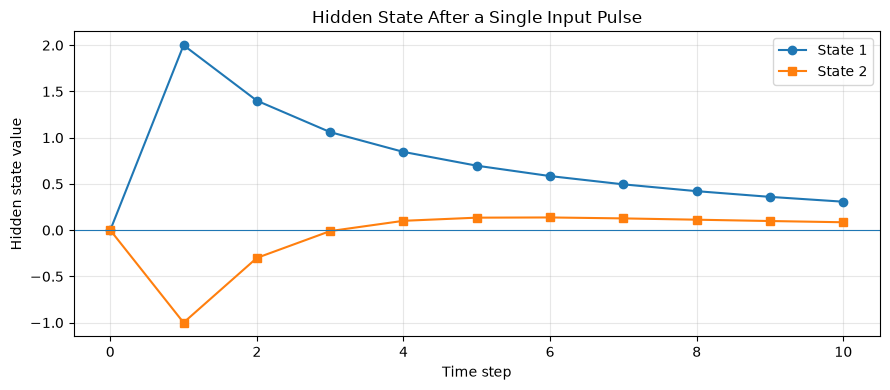

In [6]:

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(states[:, 0], marker="o", label="State 1")
ax.plot(states[:, 1], marker="s", label="State 2")

ax.axhline(0, linewidth=0.8)
ax.set_title("Hidden State After a Single Input Pulse")
ax.set_xlabel("Time step")
ax.set_ylabel("Hidden state value")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(plot_dir / "input_memory.png", dpi=160)
plt.show()
